# Issue #2 — ES Order Flow Imbalance (OFI) Predictive Research

**Goal:** test whether past top-of-book OFI predicts *subsequent* ES midprice changes at 1, 5, 10, 30, and 60 seconds.

**Data:** cleaned, complete book states from the team's `data/processed/ES/*.parquet` pipeline. **No synthetic data are substituted automatically.** Verify the source of each local Parquet file before describing findings as empirical.

**Method:** event-level Cont OFI → 1-second clock-time bins → trailing 1s/5s OFI → forward midprice change (ES ticks) → preliminary within-session HAC regressions → multi-session chronological out-of-sample validation when available. Signals are measured at the **end** of a completed second and forecasts start at that same second boundary. Quote-midpoint prediction is not executable trading P&L.

## 1. Imports and load cleaned ES data

In [10]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

from finm37000_grp2.config import SAMPLES
from finm37000_grp2.data.clean import book_states

TICK_SIZE = 0.25
HORIZONS = (1, 5, 10, 30, 60)
MAX_HORIZON = max(HORIZONS)

cwd = Path.cwd()
repo_root = next(
    (p for p in (cwd, *cwd.parents) if (p / "pyproject.toml").exists()), None
)
if repo_root is None:
    raise FileNotFoundError(
        "Cannot find pyproject.toml above the current working directory"
    )
DATA_DIR = repo_root / "data" / "processed" / "ES"
SAMPLE = "dev"  # sample name from config.SAMPLES
sample = SAMPLES[SAMPLE]
parquet_files = sorted(
    p
    for p in DATA_DIR.glob("*.parquet")
    if p.stem[:4].isdigit() and sample.start <= date.fromisoformat(p.stem) <= sample.end
)
print("Data directory:", DATA_DIR, "| sample:", SAMPLE)
print("Parquet files:", len(parquet_files))
if not parquet_files:
    raise FileNotFoundError(
        "No cleaned ES data found. Generate the sample using the "
        "project pipeline or obtain approved cleaned data "
        "from your teammate."
    )
print("First files:", [p.name for p in parquet_files[:10]])

Data directory: c:\Users\vidhi\OneDrive\Desktop\FINM\Autumn 2026\Futures\finm37000-grp-2\data\processed\ES
Parquet files: 1
First files: ['2026-10-08.parquet']


Read every clean session file in `SAMPLE` (set above; `dev` by default, which produced the outputs shown), filter to complete book states, and retain event sequence. This may require several GB of RAM for large research samples. For a quick smoke test, set `MAX_FILES = 1`; for full research, leave it `None`.

In [11]:
MAX_FILES = None  # Set to 1 for a quick smoke test; None loads all available sessions.
selected_files = parquet_files if MAX_FILES is None else parquet_files[:MAX_FILES]
parts = []
required = {
    "instrument_id",
    "sequence",
    "bid_px",
    "ask_px",
    "bid_sz",
    "ask_sz",
    "roll",
    "session_start",
}
for file_no, path in enumerate(selected_files):
    raw = pd.read_parquet(path)
    part = book_states(raw).reset_index()
    missing = required.difference(part.columns)
    if missing or "ts_event" not in part.columns:
        missing_columns = missing | (
            {"ts_event"} if "ts_event" not in part.columns else set()
        )
        raise ValueError(
            f"Invalid schema in {path.name}; missing: {sorted(missing_columns)}"
        )
    part = part[
        [
            "ts_event",
            "instrument_id",
            "sequence",
            "bid_px",
            "ask_px",
            "bid_sz",
            "ask_sz",
            "roll",
            "session_start",
        ]
    ].copy()
    part["_file_id"] = file_no
    parts.append(part)
    print(f"{path.name}: {len(part):,} complete book states")

quotes = pd.concat(parts, ignore_index=True)
quotes["ts_event"] = pd.to_datetime(quotes["ts_event"], utc=True)
quotes = quotes.sort_values(
    ["ts_event", "sequence", "_file_id"], kind="stable"
).reset_index(drop=True)
print(
    f"Total book states: {len(quotes):,}; "
    f"duplicate timestamps: {quotes['ts_event'].duplicated().sum():,}"
)
print("Contracts:", quotes["instrument_id"].nunique())
display(quotes.head())

2026-10-08.parquet: 5,860,985 complete book states
Total book states: 5,860,985; duplicate timestamps: 81
Contracts: 1


,ts_event,instrument_id,sequence,bid_px,ask_px,bid_sz,ask_sz,roll,session_start,_file_id
0,2026-10-08 13:30:00.000014289+00:00,10252,29435904,7827.0,7827.25,37,14,False,True,0
1,2026-10-08 13:30:00.000020913+00:00,10252,29435904,7827.0,7827.25,37,12,False,False,0
2,2026-10-08 13:30:00.000739557+00:00,10252,29435905,7827.0,7827.25,38,12,False,False,0
3,2026-10-08 13:30:00.000864447+00:00,10252,29435905,7827.0,7827.25,37,12,False,False,0
4,2026-10-08 13:30:00.001144485+00:00,10252,29435910,7827.0,7827.25,37,10,False,False,0


## 2. Session/contract boundaries and event-level OFI

In [12]:
# Reset at source-file boundaries, explicitly marked session/roll boundaries,
# instrument changes, and Chicago-local trading-date changes.
local_day = quotes["ts_event"].dt.tz_convert("America/Chicago").dt.date
boundary = (
    quotes["_file_id"].ne(quotes["_file_id"].shift())
    | quotes["instrument_id"].ne(quotes["instrument_id"].shift())
    | pd.Series(local_day).ne(pd.Series(local_day).shift())
    | quotes["session_start"].fillna(False).astype(bool)
    | quotes["roll"].fillna(False).astype(bool)
)
quotes["segment_id"] = boundary.cumsum().astype("int32")

prev = quotes.groupby("segment_id", sort=False)[
    ["bid_px", "ask_px", "bid_sz", "ask_sz"]
].shift()
valid_prev = prev["bid_px"].notna()

# Cont et al. best-level OFI; the first event in each segment is neutral.
bid_up = quotes["bid_px"].ge(prev["bid_px"])
bid_down = quotes["bid_px"].le(prev["bid_px"])
ask_down = quotes["ask_px"].le(prev["ask_px"])
ask_up = quotes["ask_px"].ge(prev["ask_px"])
quotes["ofi_event"] = (
    np.where(bid_up, quotes["bid_sz"], 0)
    - np.where(bid_down, prev["bid_sz"].fillna(0), 0)
    - np.where(ask_down, quotes["ask_sz"], 0)
    + np.where(ask_up, prev["ask_sz"].fillna(0), 0)
).astype("float64")
quotes.loc[~valid_prev, "ofi_event"] = 0.0
quotes["mid"] = (quotes["bid_px"] + quotes["ask_px"]) / 2

print("Segments:", quotes["segment_id"].nunique())
print("Nonzero OFI events:", int(quotes["ofi_event"].ne(0).sum()))
print("Boundary events (neutral OFI):", int(boundary.sum()))
display(quotes[["ts_event", "sequence", "segment_id", "ofi_event", "mid"]].head(10))

Segments: 1
Nonzero OFI events: 5859434
Boundary events (neutral OFI): 1


,ts_event,sequence,segment_id,ofi_event,mid
0,2026-10-08 13:30:00.000014289+00:00,29435904,1,0.0,7827.125
1,2026-10-08 13:30:00.000020913+00:00,29435904,1,2.0,7827.125
2,2026-10-08 13:30:00.000739557+00:00,29435905,1,1.0,7827.125
3,2026-10-08 13:30:00.000864447+00:00,29435905,1,-1.0,7827.125
4,2026-10-08 13:30:00.001144485+00:00,29435910,1,2.0,7827.125
5,2026-10-08 13:30:00.001179889+00:00,29435910,1,5.0,7827.125
6,2026-10-08 13:30:00.001429055+00:00,29435912,1,1.0,7827.125
7,2026-10-08 13:30:00.001430265+00:00,29435912,1,3.0,7827.125
8,2026-10-08 13:30:00.001430443+00:00,29435912,1,1.0,7827.250
9,2026-10-08 13:30:00.001724319+00:00,29435916,1,1.0,7827.250


## 3. Construct a 1-second research panel

Within each segment, `ofi_1s` sums events in the second and `mid` is the last observed book midpoint in that second (carried forward only **within** the segment). The index labels a second by its **start**, but each feature becomes observable at the **end** of that second. We therefore forecast from the end-of-second midpoint, not from its start. We do not allow returns to cross segment boundaries.

A second with no book events has zero OFI and carries the previous midpoint. Initial seconds with no valid midpoint are discarded.

In [13]:
panels = []
for seg_id, group in quotes.groupby("segment_id", sort=False):
    g = group.set_index(
        "ts_event"
    )  # duplicates are allowed; original order is preserved
    second = pd.DataFrame(
        {
            "ofi_1s": g["ofi_event"].resample("1s").sum(),
            "mid": g["mid"].resample("1s").last().ffill(),
        }
    )
    second = second.dropna(subset=["mid"])
    if second.empty:
        continue
    second["ofi_5s"] = second["ofi_1s"].rolling(5, min_periods=5).sum()
    for h in HORIZONS:
        second[f"fwd_{h}s_ticks"] = (
            second["mid"].shift(-h) - second["mid"]
        ) / TICK_SIZE
    second["segment_id"] = seg_id
    second["instrument_id"] = group["instrument_id"].iloc[0]
    second["session_date_ct"] = (
        group["ts_event"].iloc[0].tz_convert("America/Chicago").date()
    )
    panels.append(second)

if not panels:
    raise ValueError("No usable book states after filtering")
research = pd.concat(panels).rename_axis("second_start_utc").reset_index()
research = research.sort_values(
    ["second_start_utc", "segment_id"], kind="stable"
).reset_index(drop=True)
print("Second-level observations:", f"{len(research):,}")
print("Sessions (Chicago dates):", research["session_date_ct"].nunique())
print("Segments:", research["segment_id"].nunique())
display(research.head(10))

Second-level observations: 24,300
Sessions (Chicago dates): 1
Segments: 1


,second_start_utc,ofi_1s,mid,ofi_5s,fwd_1s_ticks,fwd_5s_ticks,fwd_10s_ticks,fwd_30s_ticks,fwd_60s_ticks,segment_id,instrument_id,session_date_ct
0,2026-10-08 13:30:00+00:00,136.0,7827.375,NaN,-1.0,1.0,-11.0,-6.0,-11.0,1,10252,2026-10-08
1,2026-10-08 13:30:01+00:00,-14.0,7827.125,NaN,-1.0,-3.0,-7.0,-5.0,-8.5,1,10252,2026-10-08
2,2026-10-08 13:30:02+00:00,8.0,7826.875,NaN,2.0,-2.0,-7.0,-9.0,-8.0,1,10252,2026-10-08
3,2026-10-08 13:30:03+00:00,75.0,7827.375,NaN,0.5,-4.0,-7.0,-12.5,-10.0,1,10252,2026-10-08
4,2026-10-08 13:30:04+00:00,46.0,7827.500,251.0,0.5,-6.5,-5.5,-12.5,-9.5,1,10252,2026-10-08
5,2026-10-08 13:30:05+00:00,39.0,7827.625,154.0,-5.0,-12.0,-5.0,-14.0,-11.0,1,10252,2026-10-08
6,2026-10-08 13:30:06+00:00,-184.0,7826.375,-16.0,0.0,-4.0,2.0,-11.0,-5.0,1,10252,2026-10-08
7,2026-10-08 13:30:07+00:00,-30.0,7826.375,-54.0,0.0,-5.0,0.0,-8.0,-4.5,1,10252,2026-10-08
8,2026-10-08 13:30:08+00:00,-13.0,7826.375,-142.0,-2.0,-3.0,1.0,-9.0,-4.0,1,10252,2026-10-08
9,2026-10-08 13:30:09+00:00,-152.0,7825.875,-340.0,-5.0,1.0,0.0,-4.0,-1.0,1,10252,2026-10-08


## 4. Sanity checks and descriptive statistics

In [14]:
print("OFI distribution:")
display(research[["ofi_1s", "ofi_5s"]].describe())
print("Forward returns (ticks):")
display(research[[f"fwd_{h}s_ticks" for h in HORIZONS]].describe())
print("Missing values:")
print(
    research[["ofi_1s", "ofi_5s", *[f"fwd_{h}s_ticks" for h in HORIZONS]]].isna().sum()
)

# Structural assertions: every segment's final h seconds have no h-second return.
for h in HORIZONS:
    last_h = research.groupby("segment_id", sort=False).tail(h)
    assert last_h[f"fwd_{h}s_ticks"].isna().all(), (
        f"Forward {h}s return crossed a segment"
    )
assert (quotes.loc[boundary, "ofi_event"] == 0).all(), "OFI did not reset at a boundary"
print("Boundary leakage checks passed.")

OFI distribution:


,ofi_1s,ofi_5s
count,24300.000000,24296.000000
mean,-0.486502,-2.456001
std,88.611045,202.812327
min,-1407.000000,-3496.000000
25%,-39.000000,-107.000000
50%,0.000000,0.000000
75%,38.000000,105.000000
max,1655.000000,2952.000000


Forward returns (ticks):


,fwd_1s_ticks,fwd_5s_ticks,fwd_10s_ticks,fwd_30s_ticks,fwd_60s_ticks
count,24299.000000,24295.000000,24290.000000,24270.000000,24240.000000
mean,-0.000905,-0.004425,-0.008172,-0.020087,-0.036634
std,1.103332,2.420250,3.414927,5.985458,8.643841
min,-14.000000,-22.000000,-23.500000,-33.500000,-46.000000
25%,-0.500000,-1.000000,-2.000000,-3.000000,-4.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.500000,1.000000,2.000000,3.000000,4.000000
max,38.500000,44.000000,74.000000,93.500000,93.000000


Missing values:
ofi_1s            0
ofi_5s            4
fwd_1s_ticks      1
fwd_5s_ticks      5
fwd_10s_ticks    10
fwd_30s_ticks    30
fwd_60s_ticks    60
dtype: int64
Boundary leakage checks passed.


## 5. Exploratory OFI regressions (in-sample)

OLS: future midprice movement (ticks) on a one-standard-deviation OFI increase. HAC standard errors mitigate serial correlation from overlapping returns; results are **descriptive, not out-of-sample evidence**. Regressions on a single session are especially preliminary.

In [15]:
rows = []
for feature in ("ofi_1s", "ofi_5s"):
    for h in HORIZONS:
        target = f"fwd_{h}s_ticks"
        df = research[[feature, target]].dropna()
        if len(df) < 100 or df[feature].std() == 0:
            continue
        z = (df[feature] - df[feature].mean()) / df[feature].std()
        X = sm.add_constant(z.rename(feature))
        model = sm.OLS(df[target], X).fit(
            cov_type="HAC", cov_kwds={"maxlags": max(h, 5)}
        )
        rows.append(
            {
                "feature": feature,
                "horizon_s": h,
                "beta_ticks_per_sd": model.params[feature],
                "t_stat_HAC": model.tvalues[feature],
                "p_value_HAC": model.pvalues[feature],
                "R2_in_sample": model.rsquared,
                "n_seconds": len(df),
            }
        )
regression_results = pd.DataFrame(rows)
display(regression_results.round(5))

,feature,horizon_s,beta_ticks_per_sd,t_stat_HAC,p_value_HAC,R2_in_sample,n_seconds
0,ofi_1s,1,-0.00324,-0.31189,0.75512,0.00001,24299
1,ofi_1s,5,0.00763,0.36534,0.71486,0.00001,24295
2,ofi_1s,10,-0.02466,-0.82918,0.40700,0.00005,24290
3,ofi_1s,30,0.03646,0.67394,0.50035,0.00004,24270
4,ofi_1s,60,0.05563,0.78036,0.43518,0.00004,24240
5,ofi_5s,1,0.00331,0.35653,0.72144,0.00001,24295
6,ofi_5s,5,-0.04533,-1.28480,0.19886,0.00035,24291
7,ofi_5s,10,-0.05996,-1.00002,0.31730,0.00031,24286
8,ofi_5s,30,0.07830,0.69294,0.48835,0.00017,24266
9,ofi_5s,60,0.13942,0.93120,0.35175,0.00026,24236


## 6. Visualize horizon dependence and OFI deciles

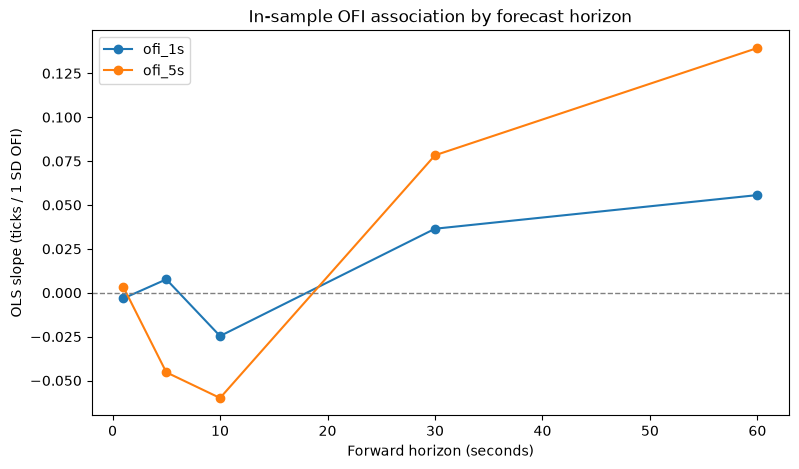

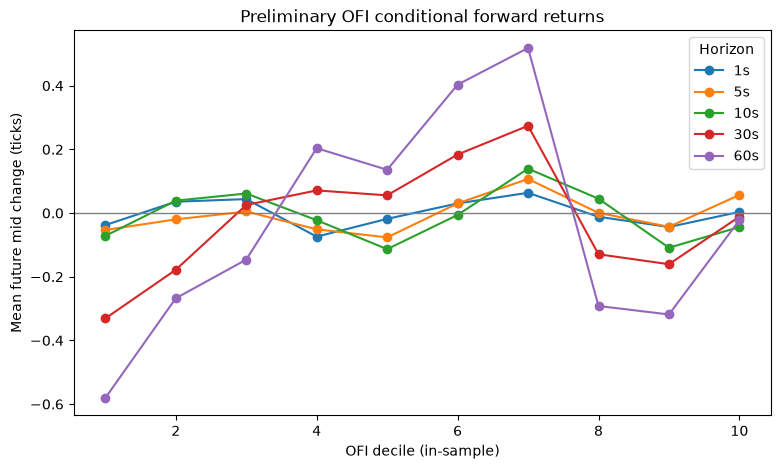

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
for feature, group in regression_results.groupby("feature"):
    ax.plot(group["horizon_s"], group["beta_ticks_per_sd"], marker="o", label=feature)
ax.axhline(0, color="gray", ls="--", lw=1)
ax.set(
    xlabel="Forward horizon (seconds)",
    ylabel="OLS slope (ticks / 1 SD OFI)",
    title="In-sample OFI association by forecast horizon",
)
ax.legend()
plt.show()

# In-sample conditional returns, NOT out-of-sample performance.
fig, ax = plt.subplots(figsize=(9, 5))
for h in HORIZONS:
    d = research[["ofi_1s", f"fwd_{h}s_ticks"]].dropna().copy()
    if d["ofi_1s"].nunique() < 10:
        continue
    d["decile"] = pd.qcut(d["ofi_1s"].rank(method="first"), 10, labels=False) + 1
    means = d.groupby("decile")[f"fwd_{h}s_ticks"].mean()
    ax.plot(means.index, means.values, marker="o", label=f"{h}s")
ax.axhline(0, color="gray", lw=1)
ax.set(
    xlabel="OFI decile (in-sample)",
    ylabel="Mean future mid change (ticks)",
    title="Preliminary OFI conditional forward returns",
)
ax.legend(title="Horizon")
plt.show()

## 7. Chronological out-of-sample test — requires multiple sessions

Train on earlier **whole Chicago trading dates**, test on later dates. Standardization and OFI decile cutoffs use training data only. We require **at least 4 trading sessions** to report this section; with only one session the notebook will explicitly skip it. The 4-day threshold is a minimal software guard, **not** a claim of adequate statistical power. Expand to many sessions for the final report.

In [17]:
dates = sorted(research["session_date_ct"].unique())
if len(dates) < 4:
    print(
        f"SKIPPED OOS: only {len(dates)} session(s) loaded; "
        "need >=4 for this notebook's preliminary split."
    )
    oos_results = pd.DataFrame()
else:
    n_train_dates = max(2, int(len(dates) * 0.75))
    n_train_dates = min(n_train_dates, len(dates) - 1)
    train_dates, test_dates = set(dates[:n_train_dates]), set(dates[n_train_dates:])
    train = research.loc[research["session_date_ct"].isin(train_dates)]
    test = research.loc[research["session_date_ct"].isin(test_dates)]
    oos_rows = []
    for feature in ("ofi_1s", "ofi_5s"):
        for h in HORIZONS:
            target = f"fwd_{h}s_ticks"
            tr = train[[feature, target]].dropna()
            te = test[[feature, target]].dropna()
            if len(tr) < 100 or len(te) < 100 or tr[feature].std() == 0:
                continue
            mu, sd = tr[feature].mean(), tr[feature].std()
            xtr = (tr[feature] - mu) / sd
            xte = (te[feature] - mu) / sd
            model = sm.OLS(tr[target], sm.add_constant(xtr.rename(feature))).fit()
            pred = model.predict(sm.add_constant(xte.rename(feature)))
            # OOS R² against the training-mean return baseline.
            baseline = tr[target].mean()
            denom = np.square(te[target] - baseline).sum()
            oos_r2 = (
                1 - np.square(te[target] - pred).sum() / denom if denom > 0 else np.nan
            )
            oos_rows.append(
                {
                    "feature": feature,
                    "horizon_s": h,
                    "train_dates": len(train_dates),
                    "test_dates": len(test_dates),
                    "train_beta_ticks_per_sd": model.params[feature],
                    "OOS_R2_vs_train_mean": oos_r2,
                    "n_test_seconds": len(te),
                }
            )
    oos_results = pd.DataFrame(oos_rows)
    print(
        f"Train: {min(train_dates)} to {max(train_dates)}; "
        f"test: {min(test_dates)} to {max(test_dates)}"
    )
    display(oos_results.round(6))

SKIPPED OOS: only 1 session(s) loaded; need >=4 for this notebook's preliminary split.


## 8. Interpretation and limitations

- **Signal timing:** current-second OFI and current-second midpoint are both known only after that second finishes. Predictions refer to *subsequent* seconds; no same-second returns are used as targets.
- **No crossing boundaries:** OFI, rolling windows, and forward returns reset at session/contract/roll/file boundaries.
- **Duplicate timestamps:** preserved; `sequence` determines event ordering.
- **Single-day caution:** HAC t-statistics on one session do not establish a stable tradable alpha. Use many days and report chronological out-of-sample results.
- **Economic relevance:** compare forecasted tick changes with the prevailing spread, fees, latency, adverse selection, and fill assumptions. Do not label quote-midpoint changes as strategy P&L.
- **Multiple testing:** 2 OFI windows × 5 horizons are examined; interpret nominal p-values cautiously.
- **Sample provenance:** offline/synthetic fixtures are for engineering tests only. Verify whether loaded Parquet files came from actual Databento historical data before reporting results.
- **Next robustness work:** evaluate daily coefficients and confidence intervals on a larger multi-session sample; check time-of-day effects, quote staleness, alternative horizons, and sensitivity to extreme OFI observations.